**Experiment 1:** Perform basic Image Handling and processing operations on
the image.

**Aim:** Read an image in python and Convert an Image to Grayscale

original image


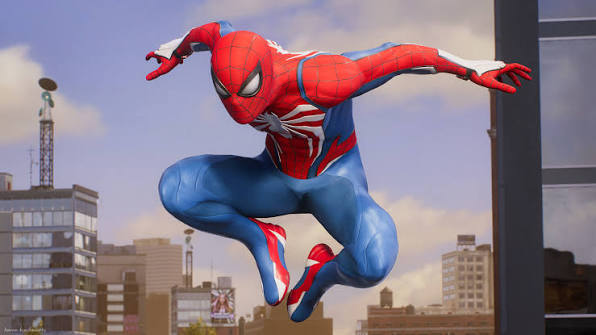

gray image


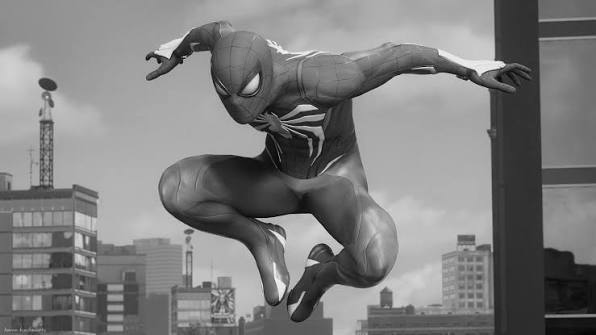

True

In [ ]:
import cv2
import urllib.request
from google.colab.patches import cv2_imshow
img = cv2.imread('spider.jpg')
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("original image")
cv2_imshow(img)
print("gray image")
cv2_imshow(gray_img)
cv2.imwrite('gray_image.jpg', gray_img)

**Experiment-2:** Perform basic Image Handling and processing operations on
the image.

**Aim:** Read an image in python and Convert an Image to Blur using GaussianBlur.

original image


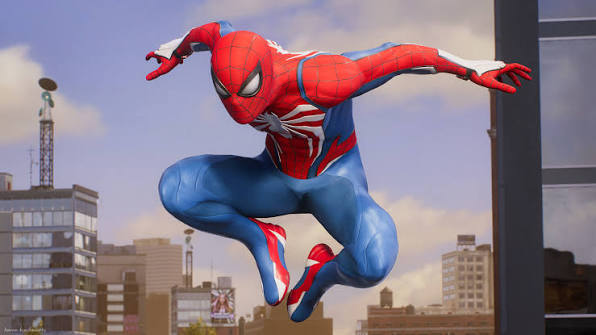

blur image


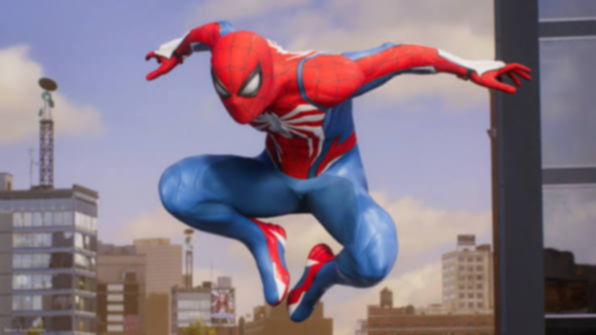

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
blur = cv2.GaussianBlur(img, (5, 5), 0)
print("original image")
cv2_imshow(img)
print("blur image")
cv2_imshow(blur)
cv2.imwrite('spider.jpg',blur)
cv2.waitKey(0)
cv2.destroyAllWindows()

**Experiment 3:**  Perform basic Image Handling and processing operations on
the image.

Aim: Read an image in python and Convert an Image to show outline using Canny
function.

Original Image


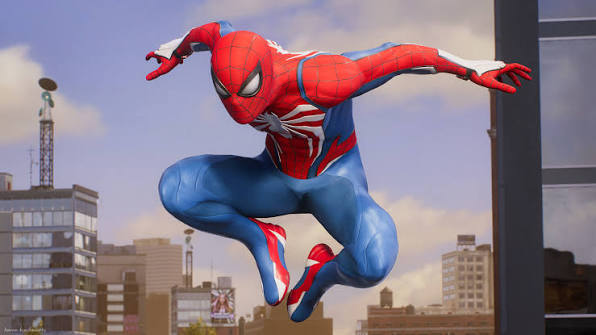

Canny Edge Detection


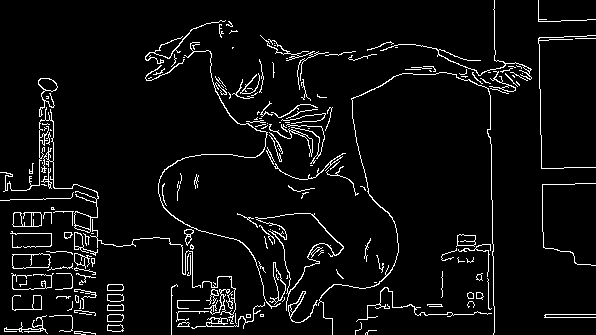

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

# Read the input image
img = cv2.imread('spider.jpg')

# Check whether the image was loaded
if img is None:
    print("Error: Image not found!")
else:
    # Convert the image to grayscale
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Detect edges using Canny
    edges = cv2.Canny(gray_img, 100, 200)

    # Display the images
    print("Original Image")
    cv2_imshow(img)
    print("Canny Edge Detection")
    cv2_imshow(edges)

    # Save the edge image
    cv2.imwrite('Canny_Edges.jpg', edges)

Experiment-4: Perform basic Image Handling and processing operations on the image.

Aim: Read an image in python  and  Dilate an Image using Dilate function.

Original Gray Image


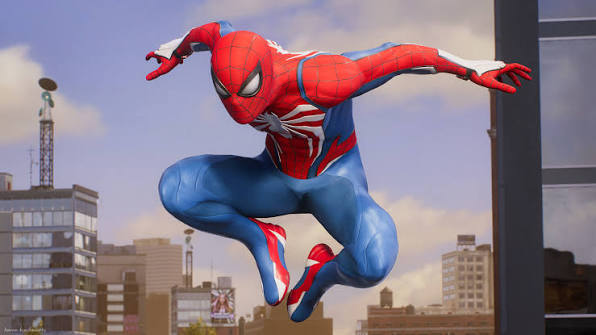

Dilated Image


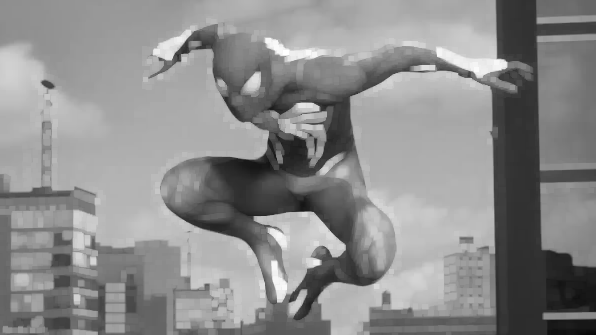

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Read the image in grayscale
img = cv2.imread("spider.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("spider.jpg")
# Check whether the image was loaded

if img is None:
    print("Error: Image not found!")
else:
    # Create a 5x5 kernel
    kernel = np.ones((5, 5), np.uint8)

    # Apply dilation
    dilated_img = cv2.dilate(img, kernel, iterations=1)

    # Display images
    print("Original Gray Image")
    cv2_imshow(img2)
    print("Dilated Image")
    cv2_imshow(dilated_img)

    # Save the output
    cv2.imwrite("Dilated_Image.jpg", dilated_img)

Experiment-5: Perform basic Image Handling and processing operations on the image.

Aim: Read an image in python  and  Erode an Image using erode function.

Original Gray Image


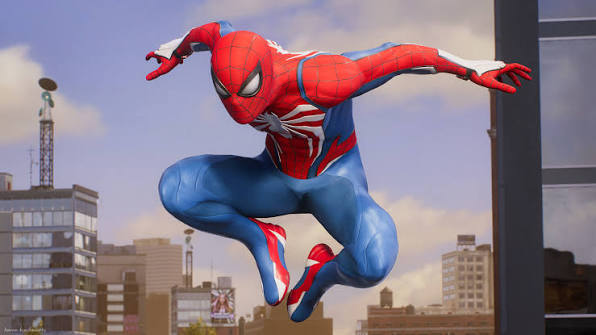

Eroded Image


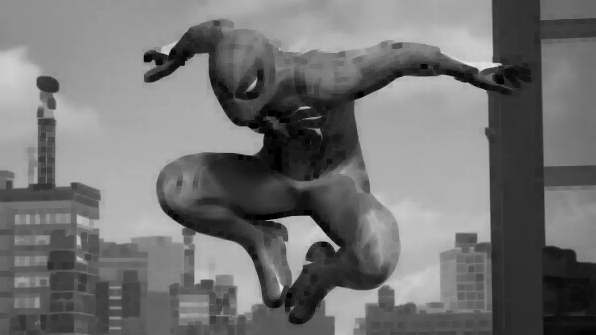

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Read the image in grayscale
img = cv2.imread("spider.jpg", cv2.IMREAD_GRAYSCALE)
img_color = cv2.imread("spider.jpg")

if img is None:
    print("Error: Image not found!")
else:
    # Create a 5x5 kernel
    kernel = np.ones((5, 5), np.uint8)

    # Apply erosion
    eroded_img = cv2.erode(img, kernel, iterations=1)

    # Display images
    print("Original Gray Image")
    cv2_imshow(img_color)
    print("Eroded Image")
    cv2_imshow(eroded_img)

    # Save the output
    cv2.imwrite("Eroded_Image.jpg", eroded_img)

Exp 6:  Perform basic video processing operations on the captured video.

Aim:Read captured video in python  and  display the video, in slow motion and in fast motion.

In [ ]:
import cv2
from google.colab import files
from IPython.display import HTML, display
from base64 import b64encode

uploaded = files.upload()
video_name = list(uploaded.keys())[0]

cap = cv2.VideoCapture(video_name)
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

if not cap.isOpened() or fps <= 0:
    raise ValueError("Unable to read the video.")

slow = cv2.VideoWriter(
    'slow_motion.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps * 0.5, (width, height)
)

fast = cv2.VideoWriter(
    'fast_motion.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps * 2.0, (width, height)
)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    slow.write(frame)
    fast.write(frame)

cap.release()
slow.release()
fast.release()

for name in ['slow_motion.mp4', 'fast_motion.mp4']:
    print(name)
    data = b64encode(open(name, 'rb').read()).decode()
    display(HTML(
        f'<video width="500" controls>'
        f'<source src="data:video/mp4;base64,{data}" '
        f'type="video/mp4"></video>'
    ))

files.download('slow_motion.mp4')
files.download('fast_motion.mp4')

Exp-7

Aim: Capture video from web Camera and  Display the video, in slow motion and in fast motion. operations on the captured video.

In [ ]:
import cv2
from google.colab import output, files
from IPython.display import display, Javascript, HTML
from base64 import b64encode
from google.colab.patches import cv2_imshow
import time

display(Javascript("""
async function recordVideo() {
    const stream = await navigator.mediaDevices.getUserMedia({video: true, audio: false});
    const video = document.createElement('video');
    video.srcObject = stream;
    video.autoplay = true;
    video.style.width = '400px';
    document.body.appendChild(video);

    await new Promise(resolve => setTimeout(resolve, 3000));

    const recorder = new MediaRecorder(stream);
    const chunks = [];
    recorder.ondataavailable = e => chunks.push(e.data);
    recorder.start();

    await new Promise(resolve => setTimeout(resolve, 5000));
    recorder.stop();

    await new Promise(resolve => recorder.onstop = resolve);
    stream.getTracks().forEach(track => track.stop());
    video.remove();

    const blob = new Blob(chunks, {type: 'video/webm'});
    const buffer = await blob.arrayBuffer();
    const bytes = new Uint8Array(buffer);
    let binary = '';
    for (let i = 0; i < bytes.length; i++) {
        binary += String.fromCharCode(bytes[i]);
    }

    google.colab.kernel.invokeFunction('notebook.saveVideo', [btoa(binary)], {});
}
recordVideo();
"""))

def save_video(data):
    with open('webcam_video.webm', 'wb') as f:
        f.write(__import__('base64').b64decode(data))

output.register_callback('notebook.saveVideo', save_video)

<IPython.core.display.Javascript object>

In [ ]:
import cv2
import time
from IPython.display import HTML, display
from base64 import b64encode
from google.colab import files

# Wait brief moment to ensure the file writing from Javascript is completed
time.sleep(2)

# Load the captured webcam video
video_name = 'webcam_video.webm'
cap = cv2.VideoCapture(video_name)

# Calculate actual FPS by counting frames
total_frames = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    total_frames += 1

# Reset video capture to the beginning
cap.release()
cap = cv2.VideoCapture(video_name)

# We recorded for 5 seconds in Javascript. Let's calculate actual FPS.
if total_frames > 0:
    fps = total_frames / 5.0
else:
    fps = 30.0

# Ensure the FPS value is realistic
if fps < 5.0 or fps > 60.0:
    fps = 30.0

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
if width == 0 or height == 0:
    width, height = 640, 480

print(f"Processing video: {total_frames} frames at calculated {fps:.2f} FPS ({width}x{height})")

# Slow motion: written at half the input FPS (rendered slower)
slow = cv2.VideoWriter(
    'webcam_slow_motion.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps * 0.5, (width, height)
)

# Fast motion: written at double the input FPS (rendered faster)
fast = cv2.VideoWriter(
    'webcam_fast_motion.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps * 2.0, (width, height)
)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    slow.write(frame)
    fast.write(frame)

cap.release()
slow.release()
fast.release()

# Display and download processed videos
for name in ['webcam_slow_motion.mp4', 'webcam_fast_motion.mp4']:
    print(f"\nDisplaying {name}:")
    data = b64encode(open(name, 'rb').read()).decode()
    display(HTML(
        f'<video width="500" controls>'
        f'<source src="data:video/mp4;base64,{data}" type="video/mp4">'
        f'</video>'
    ))
    files.download(name)

Processing video: 76 frames at calculated 15.20 FPS (640x480)

Displaying webcam_slow_motion.mp4:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Displaying webcam_fast_motion.mp4:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Exp-8: Scaling an image to its Bigger and Smaller sizes.

Aim: Converting an image to image to its Bigger and Smaller sizes.

Saving images.jpg to images (2).jpg
Original Image:


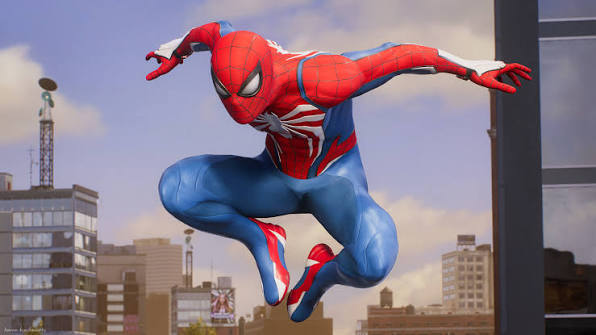

Bigger Image:


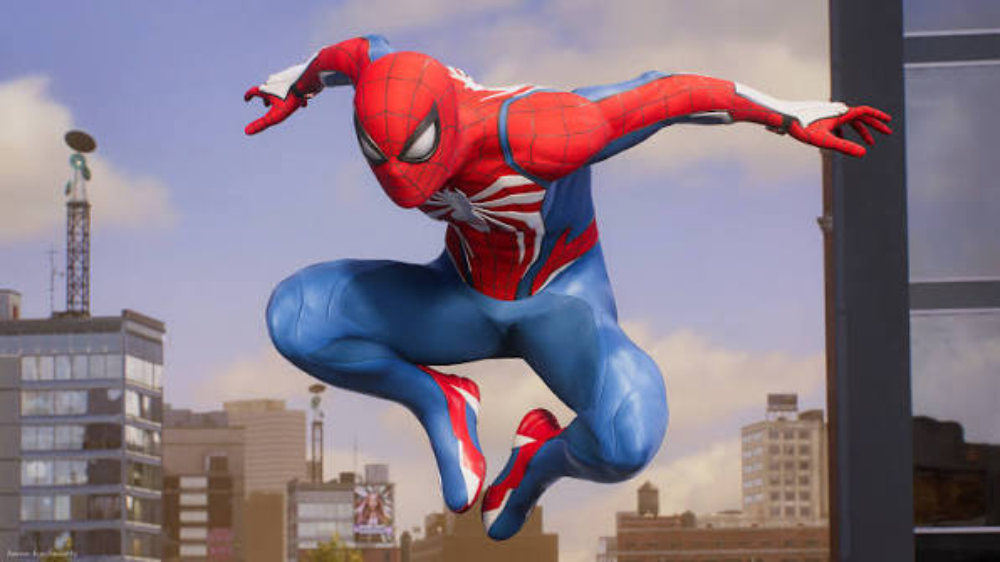

Smaller Image:


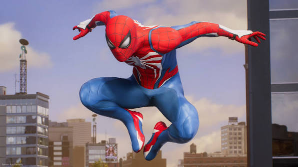

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

uploaded = files.upload()
image = cv2.imread(list(uploaded.keys())[0])

if image is None:
    raise ValueError("Unable to read the uploaded image.")

height, width = image.shape[:2]

scale_factor = 3.0
bigger_image = cv2.resize(
    image, (int(width * scale_factor), int(height * scale_factor))
)

scale_factor = 0.5
smaller_image = cv2.resize(
    image, (int(width * scale_factor), int(height * scale_factor))
)

print("Original Image:")
cv2_imshow(image)

print("Bigger Image:")
cv2_imshow(bigger_image)

print("Smaller Image:")
cv2_imshow(smaller_image)

cv2.imwrite("Bigger_image.jpg", bigger_image)
cv2.imwrite("smaller_image.jpg", smaller_image)

files.download("Bigger_image.jpg")
files.download("smaller_image.jpg")

Exp-9:  Perform Rotation of an image to clockwise and counter clockwise direction.

Aim: Rotation of an image to clockwise and counter clockwise direction.

Saving images.jpg to images.jpg
Original Image:


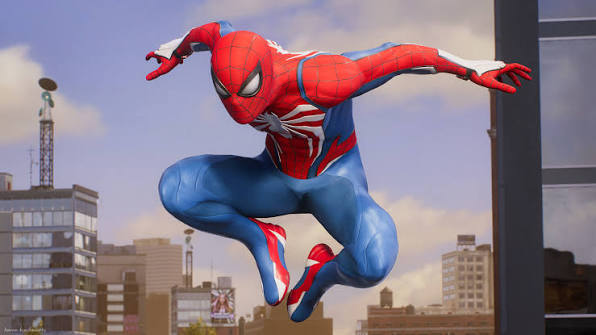

Clockwise Rotated Image:


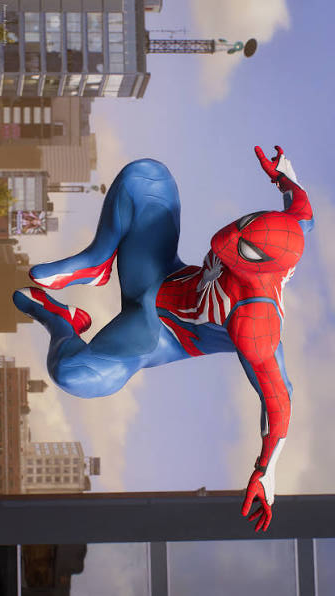

Counterclockwise Rotated Image:


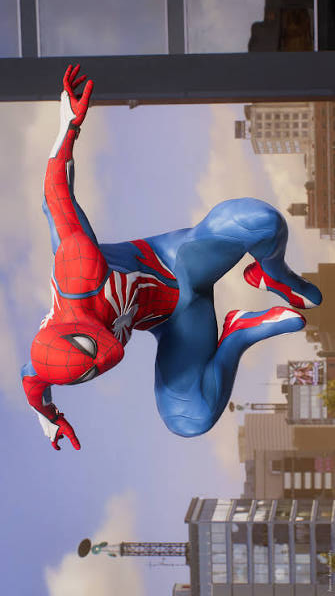

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

uploaded = files.upload()
img = cv2.imread(list(uploaded.keys())[0])

print("Original Image:")
cv2_imshow(img)

clockwise_img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

counterclockwise_img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)

print("Clockwise Rotated Image:")
cv2_imshow(clockwise_img)

print("Counterclockwise Rotated Image:")
cv2_imshow(counterclockwise_img)

cv2.imwrite("clockwise_image.jpg", clockwise_img)
cv2.imwrite("counterclockwise_image.jpg", counterclockwise_img)

files.download("clockwise_image.jpg")
files.download("counterclockwise_image.jpg")

Exp-10: Perform moving of an image from one place to another.

Aim: Moving of an image from one place to another.

Saving images.jpg to images (1).jpg
Original Image:


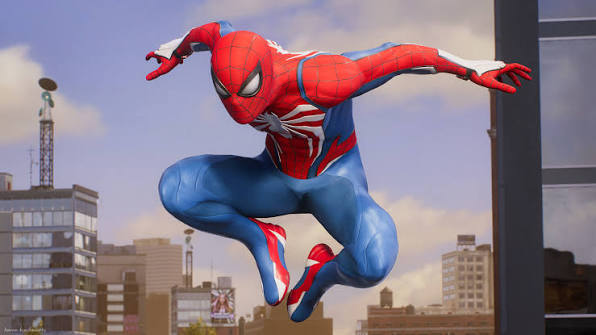

Moved Image:


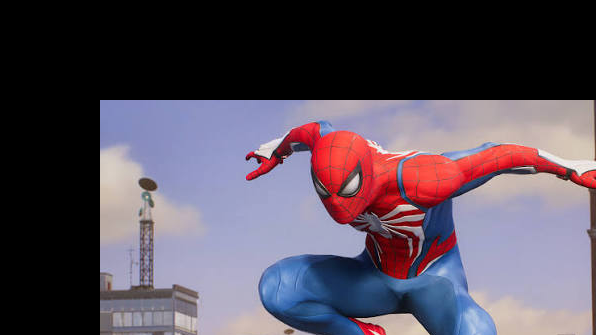

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

uploaded = files.upload()
image = cv2.imread(list(uploaded.keys())[0])

height, width = image.shape[:2]

print("Original Image:")
cv2_imshow(image)

matrix = np.float32([[1, 0, 100], [0, 1, 100]])

moved_image = cv2.warpAffine(image, matrix, (width, height))

print("Moved Image:")
cv2_imshow(moved_image)

cv2.imwrite("Moved_Image.jpg", moved_image)

files.download("Moved_Image.jpg")

Exp-11: Perform Affine Transformation on the image.

AIM:- Affine Transformation on the image

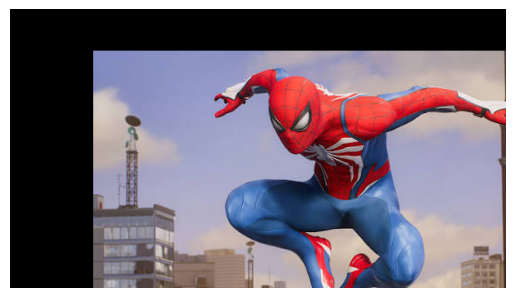

In [6]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

img = cv2.imread('spider.jpg')

rows, cols = img.shape[:2]
M = np.float32([[1, 0, 100], [0, 1, 50]])

affine_img = cv2.warpAffine(img, M, (cols, rows))

cv2.imwrite('Affine_Transformed.jpg', affine_img)

plt.imshow(cv2.cvtColor(affine_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Exp-12:Perform Perspective Transformation on the image.

AIM:- Perspective Transformation on the image.

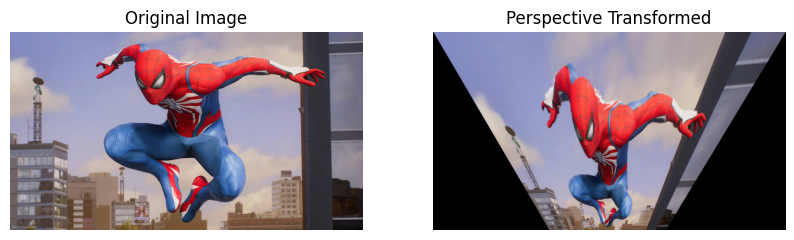

True

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
rows, cols = img.shape[:2]

src_points = np.float32([[0, 0], [cols-1, 0], [0, rows-1], [cols-1, rows-1]])
dst_points = np.float32([[0, 0], [cols-1, 0], [int(0.33*cols), rows-1], [int(0.66*cols), rows-1]])

M = cv2.getPerspectiveTransform(src_points, dst_points)
perspective_img = cv2.warpPerspective(img, M, (cols, rows))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(perspective_img, cv2.COLOR_BGR2RGB))
plt.title('Perspective Transformed')
plt.axis('off')

plt.show()

cv2.imwrite('Perspective_Transformed_Image.jpg', perspective_img)

Exp-13:Perform Perspective Transformation on the Video.

AIM:- Perspective Transformation on the Video

In [12]:
import cv2
import numpy as np

roi_points = np.array([(150, 200), (450, 200), (550, 500), (50, 500)])
target_points = np.array([(0, 0), (400, 0), (400, 600), (0, 600)])

M = cv2.getPerspectiveTransform(roi_points.astype(np.float32), target_points.astype(np.float32))

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    if not ret:
        break

    dst = cv2.warpPerspective(frame, M, (400, 600))

    cv2.imshow("Original Frame", frame)
    cv2.imshow("Transformed Frame", dst)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

Exp-14:Perform transformation using Homography matrix.

AIM:- transformation using Homography matrix

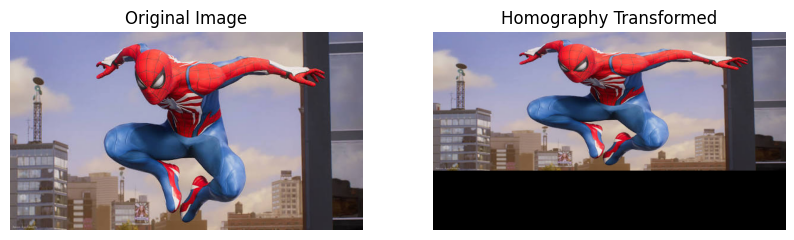

True

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
rows, cols = img.shape[:2]

src_points = np.float32([
    [0, 0],
    [cols - 1, 0],
    [0, rows - 1],
    [cols - 1, rows - 1]
])

dst_points = np.float32([
    [0, 0],
    [cols - 1, 0],
    [0, int(0.7 * rows)],
    [cols - 1, int(0.7 * rows)]
])

M, _ = cv2.findHomography(src_points, dst_points)

homography_img = cv2.warpPerspective(img, M, (cols, rows))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(homography_img, cv2.COLOR_BGR2RGB))
plt.title('Homography Transformed')
plt.axis('off')

plt.show()

cv2.imwrite('Homography_Transformed_Image.jpg', homography_img)

Exp-15:Perform transformation using Direct Linear Transformation.

AIM:- Transformation using Direct Linear Transformation.

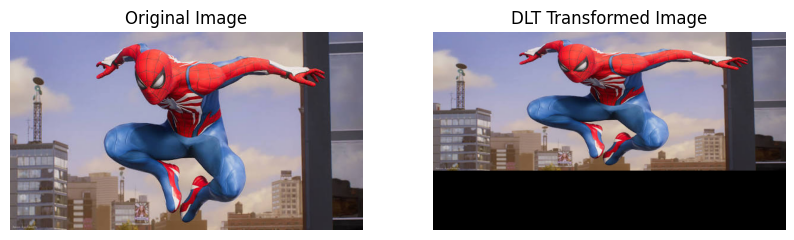

True

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
rows, cols = img.shape[:2]

src = np.float32([[0,0], [cols-1,0], [0,rows-1], [cols-1,rows-1]])
dst = np.float32([[0,0], [cols-1,0], [0,int(0.7*rows)], [cols-1,int(0.7*rows)]])

H, _ = cv2.findHomography(src, dst, 0)
transformed = cv2.warpPerspective(img, H, (cols, rows))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(transformed, cv2.COLOR_BGR2RGB))
plt.title('DLT Transformed Image')
plt.axis('off')

plt.show()

cv2.imwrite('DLT_Transformed.jpg', transformed)

Exp-16: Perform Edge detection using canny method

AIM:- Edge detection using canny method.

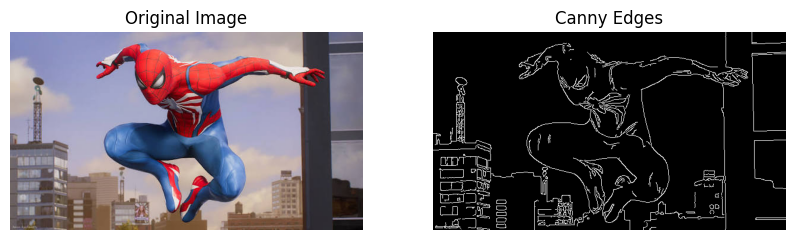

True

In [15]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(edges, cmap='gray')
plt.title('Canny Edges')
plt.axis('off')

plt.show()

cv2.imwrite('Edges.jpg', edges)

Exp-17:  Perform Edge detection using Sobel Matrix along X axis.

AIM:- Edge detection using Sobel Matrix along X axis.

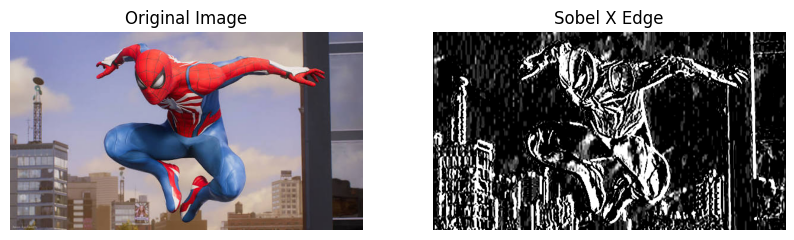

True

In [18]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray, cv2.CV_8U, 1, 0, ksize=5)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(sobel_x, cmap='gray')
plt.title('Sobel X Edge')
plt.axis('off')

plt.show()

cv2.imwrite('sobel_x.jpg', sobel_x)

Exp-18:Perform Edge detection using Sobel Matrix along Y axis

AIM:- Edge detection using Sobel Matrix along Y axis

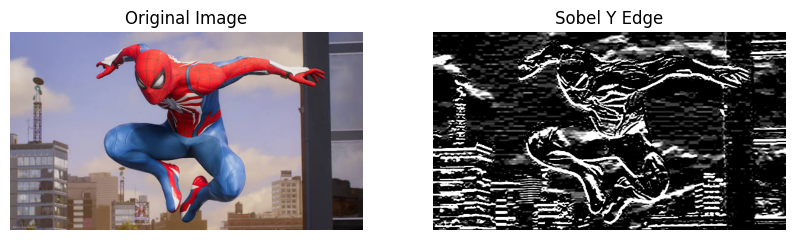

True

In [17]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_y = cv2.Sobel(gray, cv2.CV_8U, 0, 1, ksize=5)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(sobel_y, cmap='gray')
plt.title('Sobel Y Edge')
plt.axis('off')

plt.show()

cv2.imwrite('sobel_y.jpg', sobel_y)

Exp-19: Perform Edge detection using Sobel Matrix along XY axis

AIM:- Edge detection using Sobel Matrix along XY axis

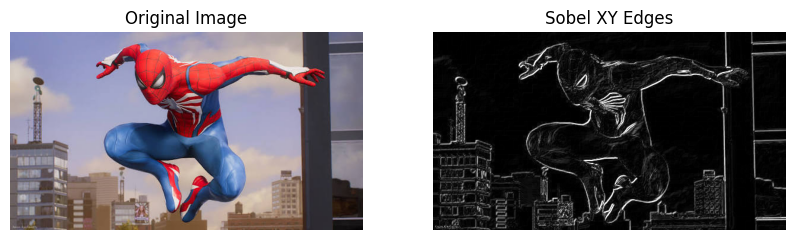

True

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

edges = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)
edges = np.uint8(np.clip(np.abs(edges), 0, 255))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(edges, cmap='gray')
plt.title('Sobel XY Edges')
plt.axis('off')

plt.show()

cv2.imwrite('Edge_detection.jpg', edges)

Exp-20: Perform Sharpening of Image using Laplacian mask with
negative center coefficient.

AIM:- Sharpening of Image using Laplacian mask with negative
center coefficient

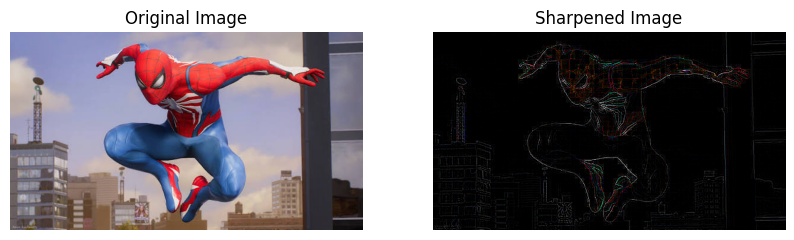

True

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = np.array([[0, 1, 0],
                   [1, -4, 1],
                   [0, 1, 0]])

sharpened = cv2.filter2D(img, -1, kernel)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(sharpened)
plt.title('Sharpened Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Sharpened_Image.jpg',
             cv2.cvtColor(sharpened, cv2.COLOR_RGB2BGR))

Exp-21:  Perform Sharpening of Image using Laplacian mask
implemented with an extension of diagonal neighbors.

AIM:- Perform Sharpening of Image using Laplacian mask
implemented with an extension of diagonal neighbors.

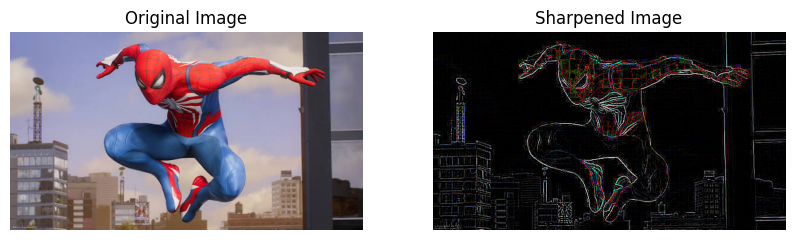

True

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = np.array([[1, 1, 1],
                   [1, -8, 1],
                   [1, 1, 1]])

sharpened = cv2.filter2D(img, -1, kernel)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(sharpened)
plt.title('Sharpened Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Sharpened_Image.jpg',
             cv2.cvtColor(sharpened, cv2.COLOR_RGB2BGR))

Exp-22:. Perform Sharpening of Image using Laplacian mask with
positive center coefficient.

AIM:- Sharpening of Image using Laplacian mask with positive
center coefficient

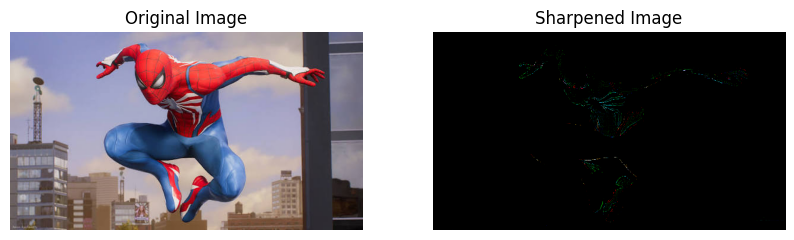

True

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = np.array([[0, 1, 0],
                   [1, -8, 1],
                   [0, 1, 0]])

sharpened = cv2.filter2D(img, -1, kernel)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(sharpened)
plt.title('Sharpened Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Sharpened_Image.jpg',
             cv2.cvtColor(sharpened, cv2.COLOR_RGB2BGR))

Exp-23:  Perform Sharpening of Image using unsharp masking.

AIM:- Sharpening of Image using unsharp masking

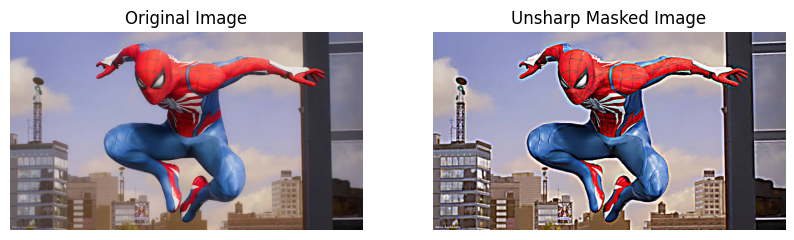

In [22]:
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter

image_path = 'spider.jpg'

im1 = Image.open(image_path)
im2 = im1.filter(ImageFilter.UnsharpMask(
    radius=3, percent=200, threshold=5))

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(im1)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(im2)
plt.title('Unsharp Masked Image')
plt.axis('off')

plt.show()

im2.save('/content/Unsharp_Masked_Image.jpg')

Exp-24: Perform Sharpening of Image using High-Boost Masks.

AIM:- Sharpening of Image using High-Boost Masks.

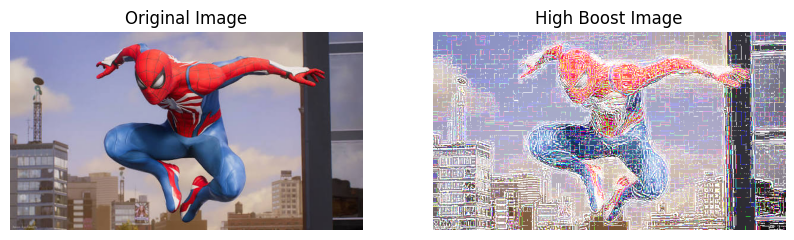

True

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def high_boost_filter(image, boost_factor):
    kernel_size = 3
    kernel = np.ones((kernel_size, kernel_size),
                     dtype=np.float32) / (kernel_size ** 2)

    blur_image = cv2.filter2D(image, -1, kernel)
    mask = image + (image - blur_image) * boost_factor

    return np.clip(mask, 0, 255).astype(np.uint8)

sharpened = high_boost_filter(img, 1.5)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(sharpened)
plt.title('High Boost Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/High_Boost_Image.jpg',
             cv2.cvtColor(sharpened, cv2.COLOR_RGB2BGR))

Exp-25:  Perform Sharpening of Image using Gradient masking.

AIM:- Sharpening of Image using Gradient masking

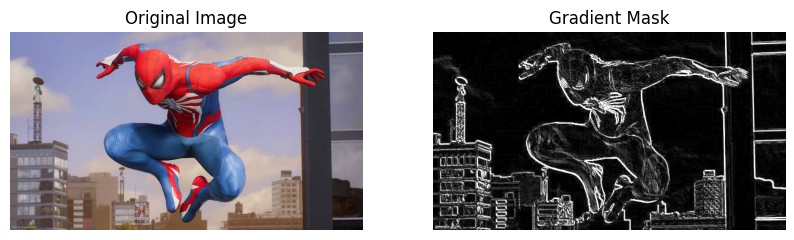

True

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('spider.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

gradient_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
gradient_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

gradient = np.abs(gradient_x - gradient_y)
gradient = np.clip(gradient, 0, 255).astype(np.uint8)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(image)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(gradient, cmap='gray')
plt.title('Gradient Mask')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Gradient_Masking.jpg', gradient)

Exp-26: Insert water marking to the image using OpenCV.

AIM:- Insert water marking to the image using OpenCV

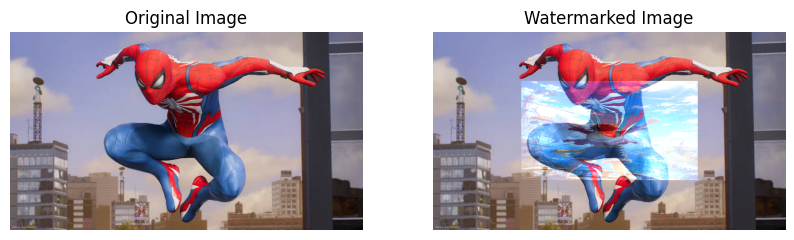

True

In [27]:
import cv2
import matplotlib.pyplot as plt

logo = cv2.imread('logo.jpg')
img = cv2.imread('spider.jpg')

h_logo, w_logo, _ = logo.shape
h_img, w_img, _ = img.shape

center_y = h_img // 2
center_x = w_img // 2

top_y = center_y - h_logo // 2
left_x = center_x - w_logo // 2

bottom_y = top_y + h_logo
right_x = left_x + w_logo

# Resize logo if it is larger than the main image
if h_logo > h_img or w_logo > w_img:
    logo = cv2.resize(logo, (w_img//2, h_img//2))
    h_logo, w_logo, _ = logo.shape
    top_y = center_y - h_logo // 2
    left_x = center_x - w_logo // 2
    bottom_y = top_y + h_logo
    right_x = left_x + w_logo

destination = img[top_y:bottom_y, left_x:right_x]

result = cv2.addWeighted(destination, 1, logo, 0.5, 0)
img[top_y:bottom_y, left_x:right_x] = result

original = cv2.cvtColor(cv2.imread('spider.jpg'),
                        cv2.COLOR_BGR2RGB)
watermarked = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(original)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(watermarked)
plt.title('Watermarked Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Watermarked_Image.jpg', img)

Exp-27: Do Cropping, Copying and pasting image inside another
image using OpenCV.

AIM:- Cropping, Copying and pasting image inside another image
using OpenCV

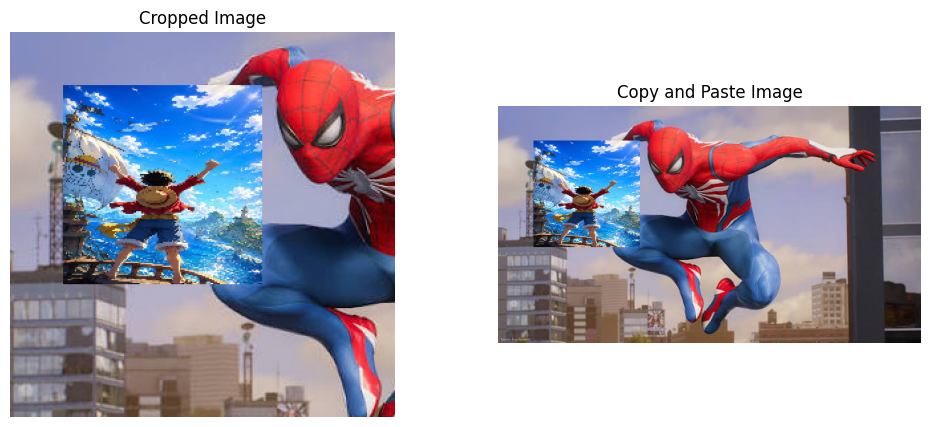

True

In [44]:
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread('spider.jpg')
img2 = cv2.imread('logo.jpg')

# Cropping
crop_img = img1[10:300, 10:300]

# Resize second image to fit
img2 = cv2.resize(img2, (150, 150))

# Copy and paste
img1[50:200, 50:200] = img2

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
plt.title('Cropped Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title('Copy and Paste Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Cropped_Image.jpg', crop_img)
cv2.imwrite('/content/Copy_Paste_Image.jpg', img1)

Exp-28: Find the boundary of the image using Convolution kernel for the given image.

AIM:- The boundary of the image using Convolution kernel for the
given image.

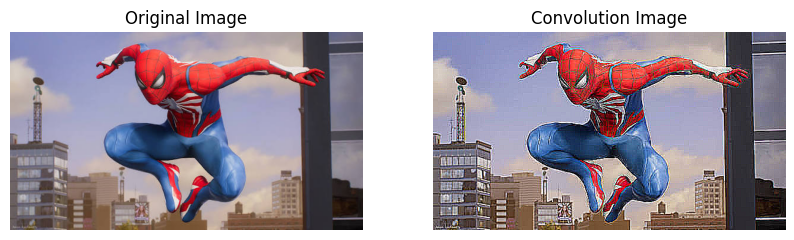

True

In [42]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = np.array([[-1, -1, -1],
                   [-1,  9, -1],
                   [-1, -1, -1]])

result = cv2.filter2D(img, -1, kernel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(result)
plt.title('Convolution Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Convolution_Image.jpg',
             cv2.cvtColor(result, cv2.COLOR_RGB2BGR))

Exp-29:  Morphological operations based on OpenCV using Erosion
technique.

AIM:- Morphological operations based on OpenCV using Erosion
technique.

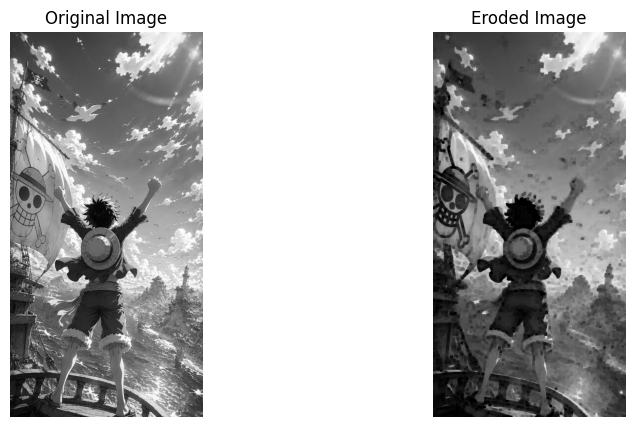

True

In [41]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('logo.jpg', cv2.IMREAD_GRAYSCALE)

kernel = np.ones((5,5), np.uint8)
eroded_img = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(eroded_img, cmap='gray')
plt.title('Eroded Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Eroded_Image.jpg', eroded_img)

Exp-30:  Morphological operations based on OpenCV using Dilation
technique.

AIM:- Morphological operations based on OpenCV using Dilation
technique.

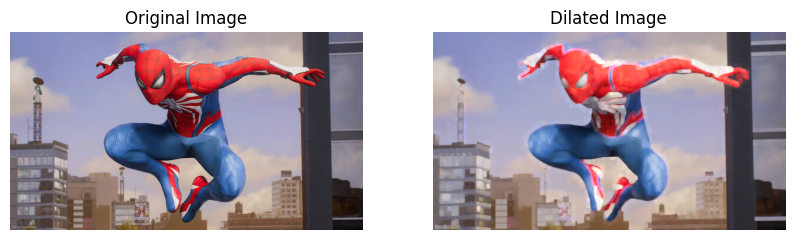

True

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('New.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = np.ones((5,5), np.uint8)
dilation = cv2.dilate(img, kernel, iterations=1)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(dilation)
plt.title('Dilated Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Dilated_Image.jpg',
             cv2.cvtColor(dilation, cv2.COLOR_RGB2BGR))

Exp-31:Morphological operations based on OpenCV using Opening
technique.

AIM:-Do morphological operations in an image

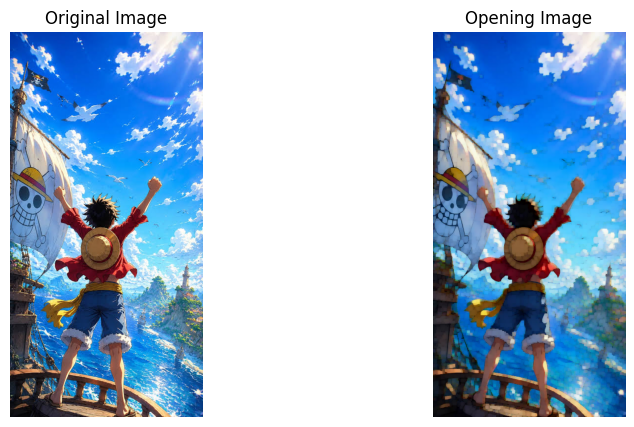

True

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('logo.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

kernel = np.ones((5,5), np.uint8)
opening = cv2.morphologyEx(img, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(opening)
plt.title('Opening Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Opened_Image.jpg',
             cv2.cvtColor(opening, cv2.COLOR_RGB2BGR))

Exp-32:Morphological operations based on OpenCV using Closing
technique.

AIM:- Morphological operations using Closing technique

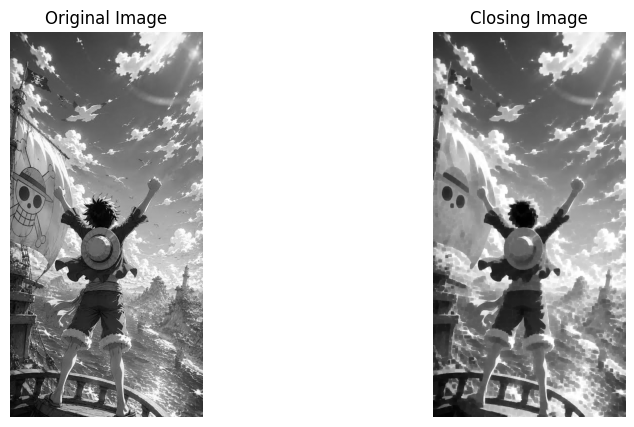

True

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('logo.jpg', cv2.IMREAD_GRAYSCALE)

kernel = np.ones((5,5), np.uint8)
closing = cv2.morphologyEx(img, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(closing, cmap='gray')
plt.title('Closing Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Closing_Image.jpg', closing)

Exp-33:  Morphological operations based on OpenCV using
Morphological Gradient technique.

AIM:- Morphological operations using Morphological Gradient
technique.

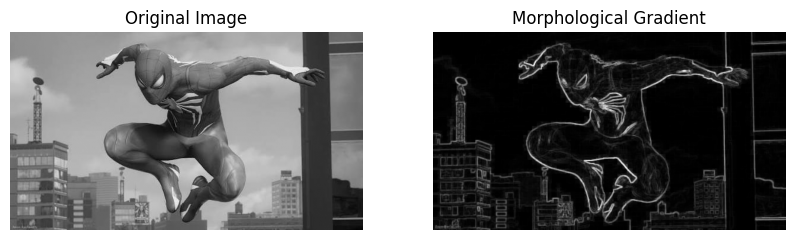

True

In [36]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('New.jpg', cv2.IMREAD_GRAYSCALE)

kernel = np.ones((3,3), np.uint8)
gradient = cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(gradient, cmap='gray')
plt.title('Morphological Gradient')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Morphological_Gradient.jpg', gradient)

Exp-34:  Morphological operations based on OpenCV using Top hat
technique.

AIM:- Morphological operations using Top hat technique.

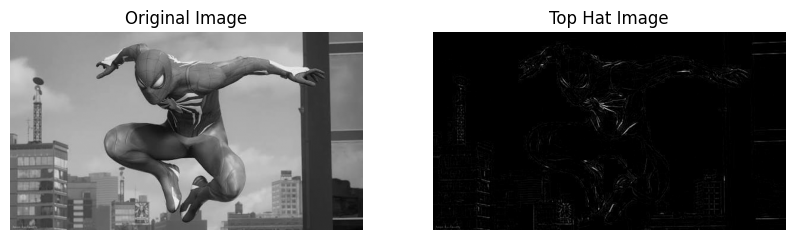

True

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg', cv2.IMREAD_GRAYSCALE)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(tophat_img, cmap='gray')
plt.title('Top Hat Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Tophat_Image.jpg', tophat_img)

Exp-35: Morphological operations based on OpenCV using Black hat
technique.

AIM:- Morphological operation using Black hat technique.

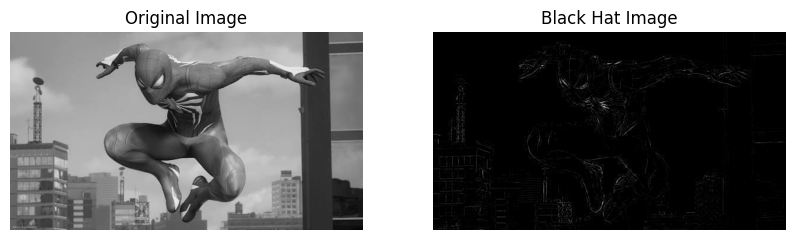

True

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('New.jpg', cv2.IMREAD_GRAYSCALE)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
blackhat_img = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(blackhat_img, cmap='gray')
plt.title('Black Hat Image')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Blackhat_Image.jpg', blackhat_img)

Exp-36:  Recognise watch from the given image by general Object
recognition using OpenCV.

AIM:- Recognise watch from the given image by general Object
recognition

Matching Score: 0.54451984167099


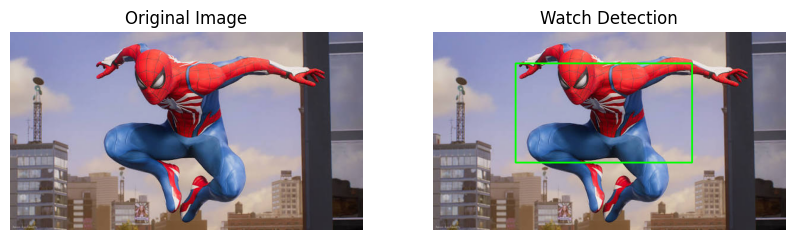

True

In [30]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('spider.jpg')
watch = cv2.imread('watch.jpg')

gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_watch = cv2.cvtColor(watch, cv2.COLOR_BGR2GRAY)

# Resize template if necessary
h, w = gray_watch.shape
H, W = gray_img.shape

if h > H or w > W:
    gray_watch = cv2.resize(gray_watch, (W//2, H//2))
    h, w = gray_watch.shape

result = cv2.matchTemplate(
    gray_img, gray_watch, cv2.TM_CCOEFF_NORMED)

_, max_val, _, max_loc = cv2.minMaxLoc(result)

top_left = max_loc
bottom_right = (top_left[0] + w, top_left[1] + h)

cv2.rectangle(img, top_left, bottom_right, (0,255,0), 2)

print("Matching Score:", max_val)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(cv2.imread('spider.jpg'),
                        cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Watch Detection')
plt.axis('off')

plt.show()

cv2.imwrite('/content/Watch_Detection.jpg', img)

Exp-37:  Using Opencv play Video in Reverse mode.

AIM:- Play Video in Reverse mode

In [ ]:
import cv2
from IPython.display import Video, display

# Read the video
cap = cv2.VideoCapture('/content/demonslayer.mp4')

frames = []
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Read all frames
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)

cap.release()

# Create reversed video
out = cv2.VideoWriter(
    '/content/reversed_video.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps,
    (width, height)
)

for frame in reversed(frames):
    out.write(frame)

out.release()

# Display reversed video
display(Video('/content/reversed_video.mp4', embed=True))

Exp-38:  Face Detection using Opencv.

AIM:- Face Detection.

In [51]:
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless
!pip install -q opencv-contrib-python

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93


In [55]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/content/image1.jpg')
result = img.copy()

# Load Haar Cascade
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = face_cascade.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=5
)

# Draw rectangles
for (x, y, w, h) in faces:
    cv2.rectangle(result, (x, y), (x+w, y+h), (0, 255, 0), 2)

# Display images
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Face Detection")
plt.axis('off')

plt.show()

cv2.imwrite('/content/face_detection.jpg', result)

AttributeError: 'NoneType' object has no attribute 'copy'

Exp-39:Vehicle Detection in a Video frame using OpenCV .

AIM:- Vehicle Detection in a Video frame

In [48]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [49]:
import cv2
from ultralytics import YOLO
from IPython.display import Video, display

# Load pretrained YOLO model
model = YOLO('yolov8n.pt')

# Read video
cap = cv2.VideoCapture('/content/video.mp4')

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

out = cv2.VideoWriter(
    '/content/vehicle_detection.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps,
    (width, height)
)

# Vehicle classes in COCO
vehicle_classes = [2, 3, 5, 7]

while True:
    ret, frame = cap.read()
    if not ret:
        break

    results = model(frame, verbose=False)

    for box in results[0].boxes:
        cls = int(box.cls[0])

        if cls in vehicle_classes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            label = model.names[cls]

            cv2.rectangle(frame, (x1, y1), (x2, y2),
                          (0, 255, 0), 2)

            cv2.putText(frame, label, (x1, y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                        (0, 255, 0), 2)

    out.write(frame)

cap.release()
out.release()

# Display resultant video
display(Video('/content/vehicle_detection.mp4', embed=True))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Exp-40: Draw Rectangular shape and extract objects.

AIM:- Draw Rectangular shape and extract objects.

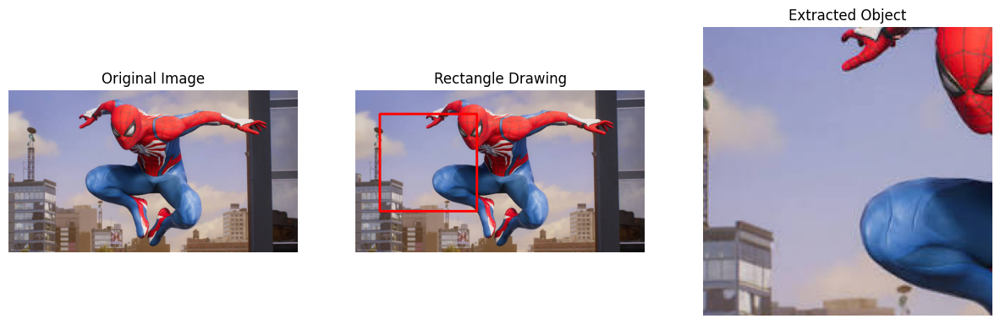

True

In [50]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('spider.jpg')
result = img.copy()

# Define rectangle coordinates
x1, y1 = 50, 50
x2, y2 = 250, 250

# Draw rectangle
cv2.rectangle(result, (x1, y1), (x2, y2),
              (0, 0, 255), 3)

# Extract object
roi = img[y1:y2, x1:x2]

# Display images
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Rectangle Drawing")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("Extracted Object")
plt.axis('off')

plt.show()

# Save outputs
cv2.imwrite('/content/rectangle_image.jpg', result)
cv2.imwrite('/content/extracted_object.jpg', roi)